# Situación Problema 1 · Actividad 4 — De los modelos a las decisiones: el futuro de Qixmora
**Michelle Hernández Brito · A01739713 · Minería de Datos · Grupo 501**

**Base:** `Qixmora_Actividad2_Base_Depurada.csv` (12,330 sesiones, 18 variables)

La dirección pregunta qué implementaríamos, cuánto valor podría generar y cómo sabríamos si funciona. La respuesta debe salir de lo que ya hicimos en las actividades anteriores. Antes de recomendar algo, reviso los puntos que el profesor marcó en la Actividad 3:

1. **Comparabilidad (C3.1):** el Frente 2 usó partición 70/30 y más predictores; el Frente 3 usó 75/25 y ocho variables. Hay que unificar predictores y partición **antes** de comparar, y la estabilidad del remuestreo solo vale para el modelo con esa misma configuración.
2. **Integración (C4.2):** faltó evidencia cuantitativa que conecte segmentos y predicciones (probabilidades promedio, proporción de compradores potenciales por cluster).
3. **Etapa 1:** no afirmar el "momento exacto" del abandono con datos agregados por sesión y verificar qué información existe en el momento de intervenir.

Este notebook es mi respaldo para el documento ejecutivo y sigue las fases de CRISP-DM.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import norm

from sklearn.model_selection import (train_test_split, StratifiedKFold, RepeatedStratifiedKFold,
                                     cross_validate, cross_val_predict)
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.naive_bayes import GaussianNB
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.utils import resample
from sklearn.metrics import (roc_auc_score, average_precision_score, recall_score, precision_score,
                             f1_score, accuracy_score, confusion_matrix, RocCurveDisplay, silhouette_score)

pd.set_option('display.float_format', '{:.3f}'.format)
sns.set_style('whitegrid')
SEMILLA = 42

## 1. Business Understanding
- Qixmora recibe ~12,000 sesiones al mes y solo usa tableros retrospectivos.
- Pregunta de negocio: **¿a qué sesiones conviene dirigir una acción mientras navegan, y qué acción?**
- Restricción: el modelo solo puede usar información que exista **en el momento de intervenir**.

## 2. Data Understanding
### 2.1 Carga y revisión

In [2]:
df = pd.read_csv('Qixmora_Actividad2_Base_Depurada.csv', encoding='utf-8-sig')
print(df.shape)
print('Nulos:', df.isna().sum().sum(), '| Duplicados:', df.duplicated().sum())
df.head()

(12330, 18)
Nulos: 0 | Duplicados: 125


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.000,0,0.000,1,0.000,0.200,0.200,0.000,0.000,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.000,0,0.000,2,64.000,0.000,0.100,0.000,0.000,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.000,0,0.000,1,0.000,0.200,0.200,0.000,0.000,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.000,0,0.000,2,2.667,0.050,0.140,0.000,0.000,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.000,0,0.000,10,627.500,0.020,0.050,0.000,0.000,Feb,3,3,1,4,Returning_Visitor,True,False


Sin nulos. Conservo los 125 duplicados, igual que en la Actividad 2: sin un identificador de sesión no puedo afirmar que sean registros repetidos (las sesiones de una página que rebotan suelen ser idénticas).

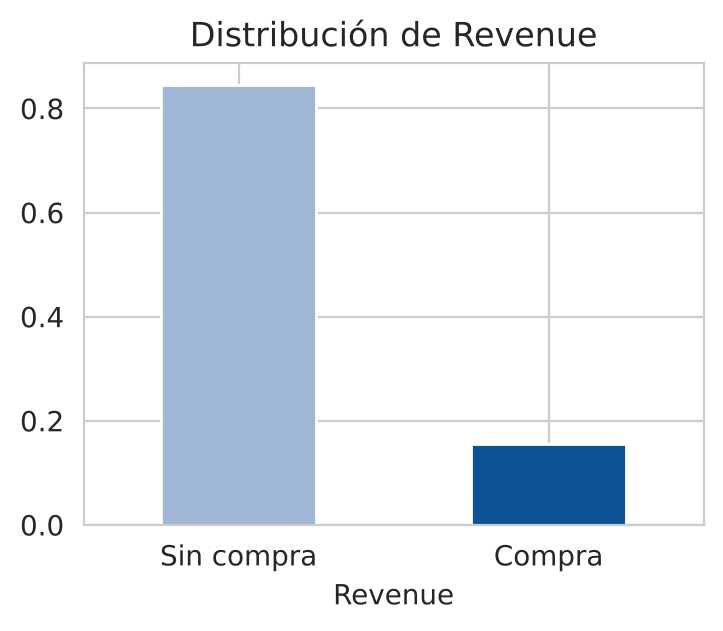

Conversión base: 15.5%  |  Accuracy de predecir siempre "no compra": 84.5%


In [3]:
tasa_base = df['Revenue'].mean()
df['Revenue'].value_counts(normalize=True).rename({False: 'Sin compra', True: 'Compra'}).plot(
    kind='bar', color=['#9fb7d4', '#0B5394'], figsize=(4, 3), title='Distribución de Revenue')
plt.xticks(rotation=0); plt.show()
print(f'Conversión base: {tasa_base:.1%}  |  Accuracy de predecir siempre "no compra": {1 - tasa_base:.1%}')

Igual que en la Actividad 3: con 15.5% de compras, la accuracy no sirve para elegir modelo. Uso **ROC-AUC** para ver qué tan bien ordena, **PR-AUC** porque la clase positiva es minoritaria y **recall / precisión** para el costo de los errores.

### 2.2 Retomo la dependencia de PageValues
En el Frente 2 concluimos que el modelo dependía de PageValues y que sin ella el ROC-AUC bajaba a 0.752. Antes de decidir si la uso, reviso por qué pesa tanto.

In [4]:
pv = df['PageValues'] > 0
print(f'Sesiones con PageValues > 0: {pv.mean():.1%}')
print(f'Conversión con PageValues > 0: {df.loc[pv, "Revenue"].mean():.1%}  vs  = 0: {df.loc[~pv, "Revenue"].mean():.1%}')
print(f'Compradores con PageValues > 0: {pv[df["Revenue"]].mean():.1%}')

Sesiones con PageValues > 0: 22.1%
Conversión con PageValues > 0: 56.3%  vs  = 0: 3.9%
Compradores con PageValues > 0: 80.6%


El 80.6% de los compradores tiene PageValues > 0, y la conversión pasa de 3.9% a 56.3%. Según el diccionario, PageValues es el valor de las páginas visitadas **antes de completar una transacción**, así que se alimenta de las páginas cercanas a la compra. Todavía no la descarto: la evalúo **con y sin** ella con el mismo protocolo.

### 2.3 Redundancia entre BounceRates y ExitRates

In [5]:
print(f"Correlación BounceRates–ExitRates: {df['BounceRates'].corr(df['ExitRates']):.2f}")

Correlación BounceRates–ExitRates: 0.91


Igual que en el Frente 2, excluyo BounceRates (r = 0.91) para no meter información duplicada al modelo.

### 2.4 ¿Qué información existe a mitad de la sesión?

In [6]:
print(df['ProductRelated'].describe()[['25%', '50%', '75%']])
llega_5 = (df['ProductRelated'] >= 5).mean()
print(f'Sesiones que llegan al menos a la 5.ª página de producto: {llega_5:.1%}')

25%    7.000
50%   18.000
75%   38.000
Name: ProductRelated, dtype: float64
Sesiones que llegan al menos a la 5.ª página de producto: 83.9%


La mediana es de 18 páginas de producto y el 83.9% llega al menos a la 5.ª, así que ese puede ser un **punto de control** para calcular el score antes de que termine la mayoría de las sesiones.

**Limitación:** los conteos y duraciones son **totales al cierre** de la sesión. En la 5.ª página serían parciales, y sin marcas de tiempo por evento no se puede saber en qué momento abandona cada visitante. Lo reporto como riesgo, no como algo resuelto.

In [7]:
pd.DataFrame({
    'Variable': ['Páginas y tiempos (admin., info., producto)', 'ExitRates', 'PageValues',
                 'Month / SpecialDay / Weekend', 'VisitorType', 'OS / Browser / Region / TrafficType'],
    'Disponible a mitad de sesión': ['Sí, pero parcial', 'Sí (promedio histórico por página)', 'Dudosa',
                                     'Sí', 'Sí', 'Sí'],
    'Uso': ['Predictor', 'Predictor', 'Solo escenario de comparación', 'Predictor (contexto)', 'Predictor (contexto)',
            'Excluidas, como en la Act. 3 (códigos técnicos)'],
    '¿Palanca?': ['Parcial: contenido y recomendaciones', 'Parcial: rediseñar páginas con alta salida', 'No',
                  'No: sirve para calendarizar', 'No', 'TrafficType podría serlo: pendiente']})

,Variable,Disponible a mitad de sesión,Uso,¿Palanca?
0,"Páginas y tiempos (admin., info., producto)","Sí, pero parcial",Predictor,Parcial: contenido y recomendaciones
1,ExitRates,Sí (promedio histórico por página),Predictor,Parcial: rediseñar páginas con alta salida
2,PageValues,Dudosa,Solo escenario de comparación,No
3,Month / SpecialDay / Weekend,Sí,Predictor (contexto),No: sirve para calendarizar
4,VisitorType,Sí,Predictor (contexto),No
5,OS / Browser / Region / TrafficType,Sí,"Excluidas, como en la Act. 3 (códigos técnicos)",TrafficType podría serlo: pendiente


## 3. Data Preparation — un solo protocolo
Para corregir la observación C3.1, **todos** los modelos usan exactamente lo mismo:
- Los predictores del Frente 2: páginas y tiempos (administrativos, informativos y de producto), ExitRates, SpecialDay, Month, VisitorType y Weekend (+ PageValues solo en el escenario A).
- Partición estratificada **70/30**, semilla 42 (la del Frente 2).
- Validación cruzada estratificada de 5 pliegues solo en entrenamiento.
- `log1p` + estandarización en numéricas y one-hot en categóricas, dentro de un pipeline para no filtrar información de prueba.

In [8]:
numericas = ['Administrative', 'Administrative_Duration', 'Informational', 'Informational_Duration',
             'ProductRelated', 'ProductRelated_Duration', 'ExitRates', 'SpecialDay']
categoricas = ['Month', 'VisitorType', 'Weekend']
y = df['Revenue'].astype(int)

def preparar_X(cols_num):
    X = df[cols_num + categoricas].copy()
    X['Weekend'] = X['Weekend'].astype(str)
    return X

def preprocesador(cols_num):
    num = Pipeline([('log', FunctionTransformer(np.log1p)), ('escala', StandardScaler())])
    return ColumnTransformer([('n', num, cols_num),
                              ('c', OneHotEncoder(handle_unknown='ignore', sparse_output=False), categoricas)])

## 4. Modeling
Comparo los tres clasificadores del Frente 3 (regresión logística, LDA y Naive Bayes gaussiano), ahora con el protocolo único. Reporto el umbral de 0.50 y el de **0.20**, que fue el que elegimos en la Actividad 3.

In [9]:
def modelos():
    return {'Regresión logística': LogisticRegression(max_iter=3000),
            'LDA': LinearDiscriminantAnalysis(),
            'Naive Bayes': GaussianNB()}

def evaluar(cols_num, escenario):
    X = preparar_X(cols_num)
    X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.30, stratify=y, random_state=SEMILLA)
    cv = StratifiedKFold(5, shuffle=True, random_state=SEMILLA)
    filas, ajustados = [], {}
    for nombre, m in modelos().items():
        pipe = Pipeline([('prep', preprocesador(cols_num)), ('modelo', m)])
        auc_cv = cross_validate(pipe, X_tr, y_tr, cv=cv, scoring='roc_auc')['test_score']
        pipe.fit(X_tr, y_tr)
        prob = pipe.predict_proba(X_te)[:, 1]
        fila = {'Escenario': escenario, 'Modelo': nombre,
                'AUC prueba': roc_auc_score(y_te, prob), 'AUC CV': auc_cv.mean(), 'DE CV': auc_cv.std(),
                'AUC entren.': roc_auc_score(y_tr, pipe.predict_proba(X_tr)[:, 1]),
                'PR-AUC': average_precision_score(y_te, prob)}
        for u in [0.5, 0.2]:
            pred = (prob >= u).astype(int)
            vn, fp, fn, vp = confusion_matrix(y_te, pred).ravel()
            fila.update({f'Recall@{u}': recall_score(y_te, pred), f'Precisión@{u}': precision_score(y_te, pred, zero_division=0),
                         f'F1@{u}': f1_score(y_te, pred), f'Accuracy@{u}': accuracy_score(y_te, pred),
                         f'VP@{u}': vp, f'FP@{u}': fp, f'FN@{u}': fn})
        filas.append(fila); ajustados[nombre] = (pipe, prob)
    return pd.DataFrame(filas), ajustados, (X_tr, X_te, y_tr, y_te)

### 4.1 Escenario A: con PageValues (verificación contra el Frente 2)

In [10]:
res_A, mod_A, datos_A = evaluar(numericas + ['PageValues'], 'Con PageValues')
res_A[['Modelo', 'AUC prueba', 'AUC CV', 'DE CV', 'PR-AUC', 'Recall@0.5', 'Precisión@0.5', 'Accuracy@0.5']]

,Modelo,AUC prueba,AUC CV,DE CV,PR-AUC,Recall@0.5,Precisión@0.5,Accuracy@0.5
0,Regresión logística,0.911,0.917,0.009,0.654,0.544,0.696,0.893
1,LDA,0.910,0.916,0.009,0.652,0.647,0.637,0.888
2,Naive Bayes,0.842,0.857,0.011,0.541,0.836,0.322,0.702


La regresión logística reproduce lo del Frente 2 (AUC de prueba 0.911; CV 0.917; recall 0.54; precisión 0.70; accuracy 0.89), lo que confirma que el protocolo es el mismo. Con PageValues, logística y LDA quedan casi empatadas.

### 4.2 Escenario B: sin PageValues

In [11]:
res_B, mod_B, datos_B = evaluar(numericas, 'Sin PageValues')
res_B[['Modelo', 'AUC prueba', 'AUC CV', 'DE CV', 'AUC entren.', 'PR-AUC']]

,Modelo,AUC prueba,AUC CV,DE CV,AUC entren.,PR-AUC
0,Regresión logística,0.742,0.753,0.007,0.758,0.315
1,LDA,0.726,0.730,0.008,0.735,0.303
2,Naive Bayes,0.707,0.718,0.008,0.724,0.261


In [12]:
cols_u = ['Modelo', 'Recall@0.5', 'Precisión@0.5', 'VP@0.5', 'FP@0.5', 'Recall@0.2', 'Precisión@0.2', 'F1@0.2', 'VP@0.2', 'FP@0.2', 'FN@0.2']
res_B[cols_u]

,Modelo,Recall@0.5,Precisión@0.5,VP@0.5,FP@0.5,Recall@0.2,Precisión@0.2,F1@0.2,VP@0.2,FP@0.2,FN@0.2
0,Regresión logística,0.007,0.333,4,8,0.612,0.292,0.395,350,849,222
1,LDA,0.009,0.357,5,9,0.517,0.288,0.370,296,730,276
2,Naive Bayes,0.773,0.243,442,1377,0.844,0.223,0.353,483,1685,89


**Lectura:**
- Sin PageValues el AUC cae de ~0.91 a ~0.74: la mayor parte del poder predictivo dependía de PageValues, como advertimos en el Frente 2.
- Con el mismo protocolo, la **logística ordena mejor** (AUC 0.742; CV 0.753 ± 0.007) que LDA (0.726) y Naive Bayes (0.707). Coincide con el orden del Frente 3, aunque ahí los AUC eran más bajos.
- Con umbral 0.50, la logística y LDA casi no detectan compradores (4 y 5 de 572), igual que en el Frente 3. Con el umbral de 0.20 la logística detecta 350 (recall 0.61) con el mejor F1 (0.40). El problema sigue siendo el umbral, no el modelo.
- La brecha entrenamiento–prueba es pequeña (0.758 vs 0.742): no hay sobreajuste.

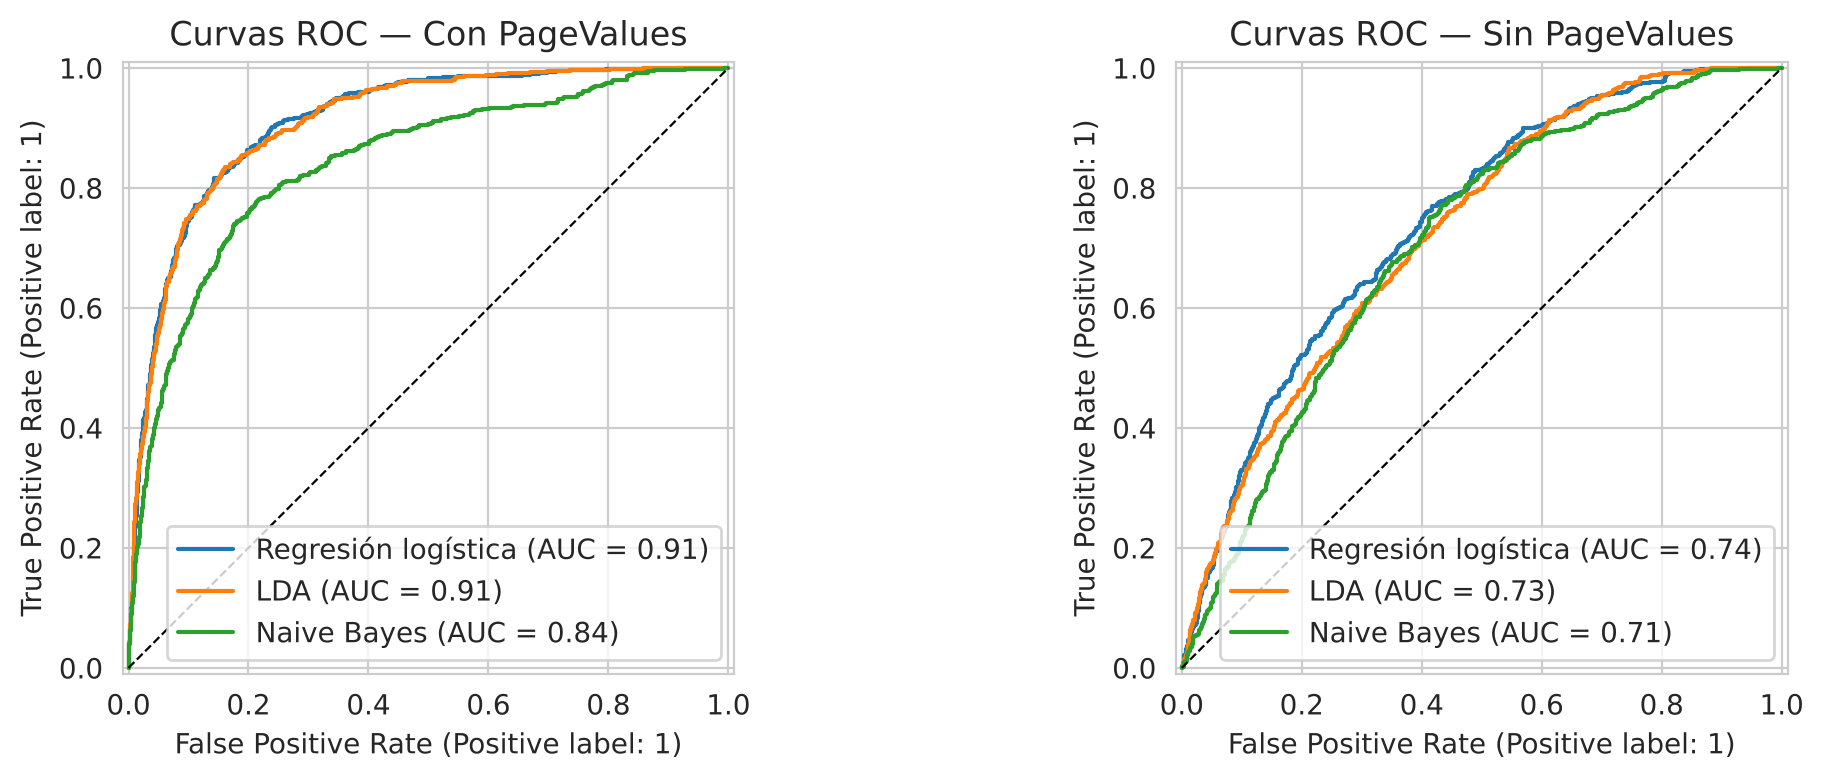

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, (mods, datos, titulo) in zip(axes, [(mod_A, datos_A, 'Con PageValues'), (mod_B, datos_B, 'Sin PageValues')]):
    for nombre, (_, prob) in mods.items():
        RocCurveDisplay.from_predictions(datos[3], prob, name=nombre, ax=ax)
    ax.plot([0, 1], [0, 1], 'k--', lw=0.8); ax.set_title(f'Curvas ROC — {titulo}')
plt.tight_layout(); plt.show()

### 4.3 ¿Por qué el AUC del Frente 3 era más bajo?
El Frente 3 usó solo las ocho variables de navegación. Lo pruebo con la misma partición 70/30 para separar el efecto de las variables del efecto de la partición.

In [14]:
nav8 = ['Administrative', 'Administrative_Duration', 'Informational', 'Informational_Duration',
        'ProductRelated', 'ProductRelated_Duration', 'BounceRates', 'ExitRates']
X8_tr, X8_te, y8_tr, y8_te = train_test_split(df[nav8], y, test_size=0.30, stratify=y, random_state=SEMILLA)
lr8 = Pipeline([('log', FunctionTransformer(np.log1p)), ('esc', StandardScaler()),
                ('m', LogisticRegression(max_iter=3000))]).fit(X8_tr, y8_tr)
print(f'Logística solo con 8 variables de navegación: AUC = {roc_auc_score(y8_te, lr8.predict_proba(X8_te)[:, 1]):.3f}')

Logística solo con 8 variables de navegación: AUC = 0.711


Solo con navegación el AUC es 0.711. Agregar contexto que sí existe durante la sesión (mes, tipo de visitante, fin de semana, fecha especial) lo sube a 0.742 sin usar PageValues.

### 4.4 Selección y estabilidad del modelo final
Elijo la **regresión logística sin PageValues**: es la que mejor ordena con el mismo protocolo, solo usa información disponible antes de la compra y es una fórmula que el equipo web puede programar. Como pidió el profesor, repito el remuestreo **con esta misma configuración** (validación cruzada 5 × 10 y bootstrap de 500 réplicas evaluado en las observaciones fuera de la muestra, *out-of-bag*), en lugar de heredar la estabilidad del Frente 2.

In [15]:
X_tr, X_te, y_tr, y_te = datos_B
modelo_final, prob_test = mod_B['Regresión logística']

def pipe_final():
    return Pipeline([('prep', preprocesador(numericas)), ('modelo', LogisticRegression(max_iter=3000))])

cv_rep = cross_validate(pipe_final(), X_tr, y_tr, scoring=['roc_auc', 'average_precision'],
                        cv=RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=SEMILLA))

nombres_coef = [f'num__{c}' for c in numericas] + list(
    modelo_final.named_steps['prep'].named_transformers_['c'].get_feature_names_out())
auc_boot, coefs_boot = [], []
rng = np.random.RandomState(SEMILLA)
for b in range(500):
    idx = resample(np.arange(len(X_tr)), replace=True, random_state=rng)
    oob = np.setdiff1d(np.arange(len(X_tr)), idx)
    m = pipe_final().fit(X_tr.iloc[idx], y_tr.iloc[idx])
    auc_boot.append(roc_auc_score(y_tr.iloc[oob], m.predict_proba(X_tr.iloc[oob])[:, 1]))
    coefs_boot.append(m.named_steps['modelo'].coef_[0])
auc_boot = np.array(auc_boot); coefs_boot = pd.DataFrame(coefs_boot, columns=nombres_coef)

print(f"CV 5x10 ROC-AUC: {cv_rep['test_roc_auc'].mean():.3f} ± {cv_rep['test_roc_auc'].std():.3f}")
print(f"CV 5x10 PR-AUC:  {cv_rep['test_average_precision'].mean():.3f} ± {cv_rep['test_average_precision'].std():.3f}")
print(f"Bootstrap OOB ROC-AUC: {auc_boot.mean():.3f} ± {auc_boot.std():.3f}  (IC 95%: {np.percentile(auc_boot, 2.5):.3f}–{np.percentile(auc_boot, 97.5):.3f})")
print(f"Prueba (referencia): {roc_auc_score(y_te, prob_test):.3f}")

CV 5x10 ROC-AUC: 0.752 ± 0.013
CV 5x10 PR-AUC:  0.342 ± 0.020
Bootstrap OOB ROC-AUC: 0.751 ± 0.009  (IC 95%: 0.734–0.768)
Prueba (referencia): 0.742


In [16]:
signo = (np.sign(coefs_boot) == np.sign(coefs_boot.mean())).mean()
estab = pd.DataFrame({'coef. medio': coefs_boot.mean(), '% réplicas con el mismo signo': signo})
estab.loc[['num__ExitRates', 'num__ProductRelated_Duration', 'Month_Nov', 'Month_Feb', 'VisitorType_Returning_Visitor']]

,coef. medio,% réplicas con el mismo signo
num__ExitRates,-1.302,1.000
num__ProductRelated_Duration,0.585,1.000
Month_Nov,0.579,1.000
Month_Feb,-1.243,1.000
VisitorType_Returning_Visitor,-0.618,1.000


La validación cruzada repetida y el bootstrap coinciden, con una variación muy baja. ExitRates, la duración en páginas de producto, noviembre, febrero y ser visitante recurrente mantienen su signo en prácticamente todas las réplicas. Ahora la estabilidad sí corresponde al modelo que voy a recomendar.

### 4.5 Umbral: ¿cuánto cuesta cada acierto?

In [17]:
for u in [0.5, 0.2]:
    vn, fp, fn, vp = confusion_matrix(y_te, (prob_test >= u).astype(int)).ravel()
    print(f'Umbral {u}: VP={vp}, FP={fp}, FN={fn} -> {fp / max(vp, 1):.1f} falsos positivos por cada comprador detectado')

Umbral 0.5: VP=4, FP=8, FN=568 -> 2.0 falsos positivos por cada comprador detectado
Umbral 0.2: VP=350, FP=849, FN=222 -> 2.4 falsos positivos por cada comprador detectado


Con el umbral de 0.20 de la Actividad 3 hay **849 falsos positivos para 350 compradores detectados** (2.4 a 1). Si a todos se les diera un incentivo, la mayor parte se gastaría en personas que no compran. En lugar de un umbral fijo, pruebo **bandas por ranking** para que el presupuesto sea predecible.

In [18]:
bandas = pd.qcut(prob_test, q=[0, 0.5, 0.8, 1.0], labels=['Baja (50%)', 'Media (30%)', 'Alta (20%)'])
tb = (pd.DataFrame({'banda': bandas, 'compra': y_te.values, 'prob': prob_test})
        .groupby('banda', observed=True)
        .agg(sesiones=('compra', 'size'), conversion=('compra', 'mean'), compras=('compra', 'sum'),
             prob_media=('prob', 'mean'), prob_min=('prob', 'min')))
tb['% de compras'] = tb['compras'] / y_te.sum()
tb['lift'] = tb['conversion'] / tasa_base
tb

,sesiones,conversion,compras,prob_media,prob_min,% de compras,lift
banda,,,,,,,
Baja (50%),1850,0.066,123,0.060,0.000,0.215,0.430
Media (30%),1109,0.173,192,0.192,0.139,0.336,1.119
Alta (20%),740,0.347,257,0.339,0.252,0.449,2.244


- **Banda alta** (20%, probabilidad ≥ 0.25): convierte al **34.7%** (2.2 veces la base) y concentra el **44.9%** de las compras.
- **Banda media** (30%, 0.14–0.25): convierte al 17.3% y reúne otro 33.6%.
- **Banda baja** (50%): 6.6% de conversión.

Como la logística no tiene pesos de clase, la probabilidad promedio de cada banda coincide con su conversión real (0.34 vs 34.7%; 0.19 vs 17.3%; 0.06 vs 6.6%): las probabilidades se pueden leer como tales.

### 4.6 Coeficientes: lo predictivo vs. lo accionable

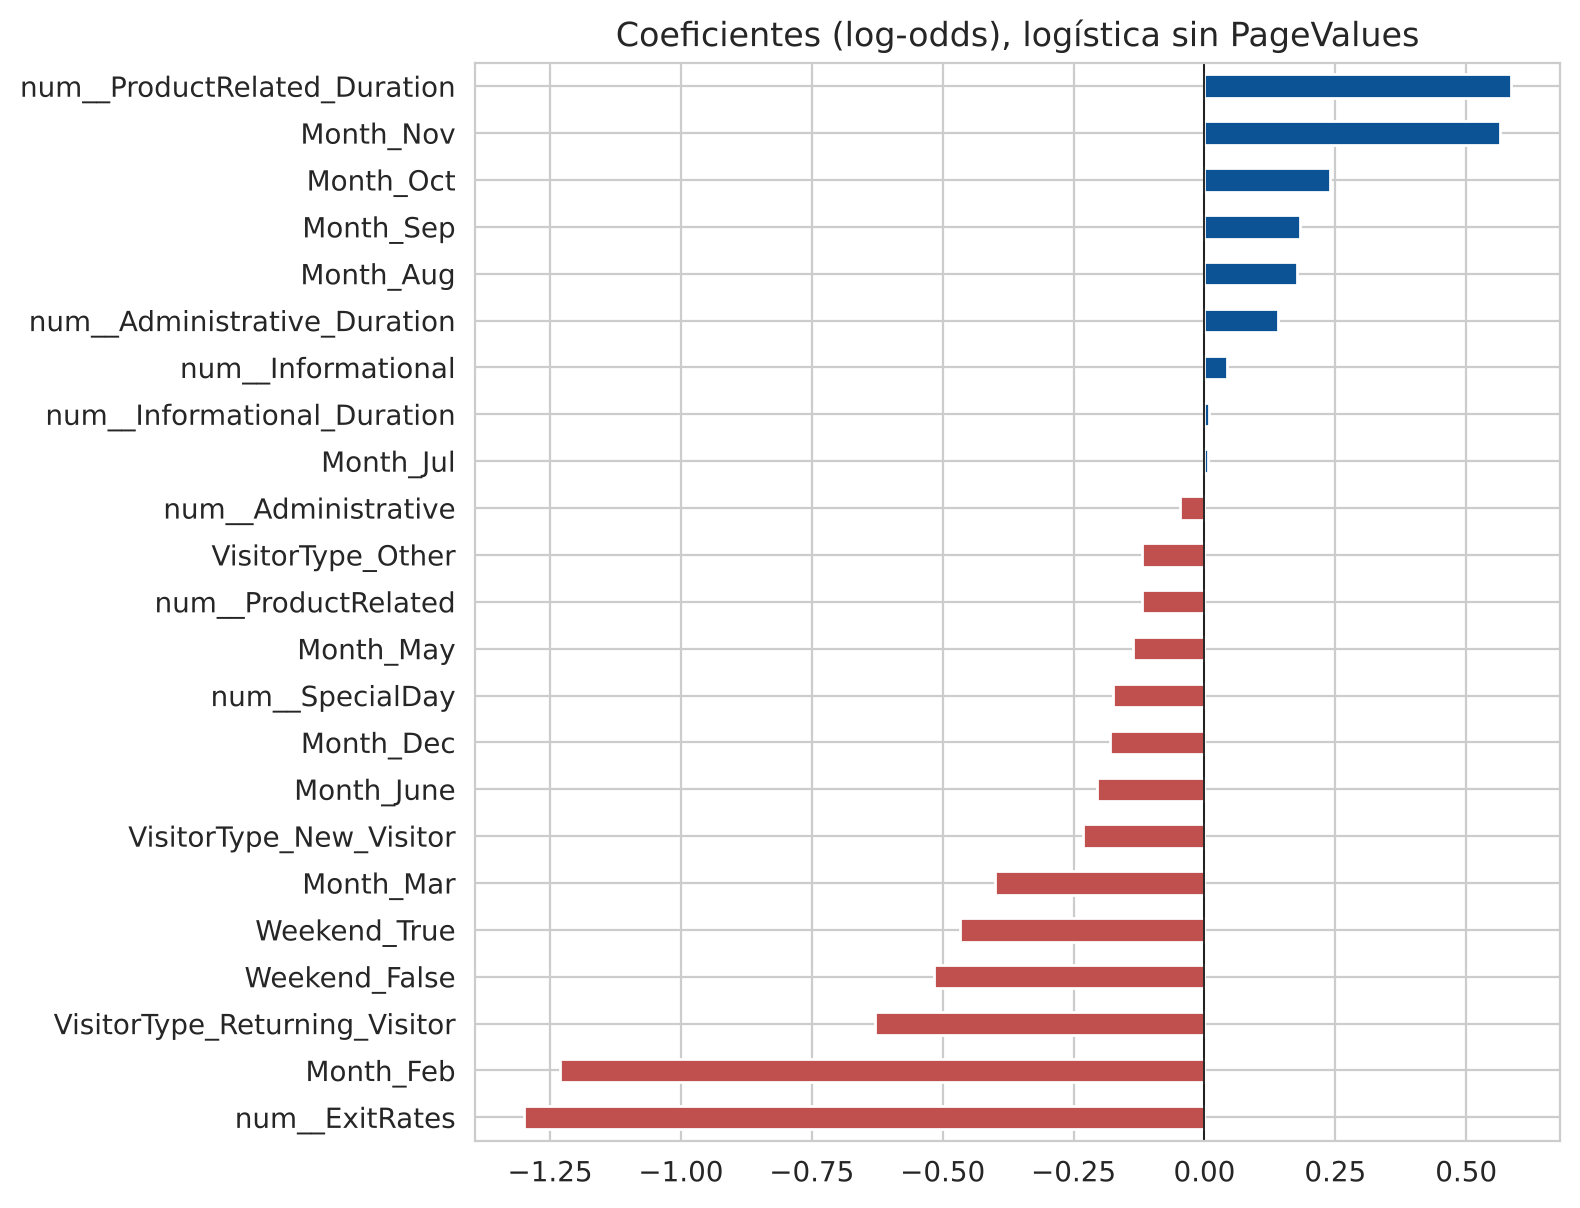

num__ExitRates                  -1.300
Month_Feb                       -1.230
VisitorType_Returning_Visitor   -0.630
Weekend_False                   -0.520
Weekend_True                    -0.470
Month_Mar                       -0.400
VisitorType_New_Visitor         -0.230
Month_June                      -0.210
Month_Dec                       -0.180
num__SpecialDay                 -0.180
Month_May                       -0.140
num__ProductRelated             -0.120
VisitorType_Other               -0.120
num__Administrative             -0.050
Month_Jul                        0.010
num__Informational_Duration      0.010
num__Informational               0.040
num__Administrative_Duration     0.140
Month_Aug                        0.180
Month_Sep                        0.180
Month_Oct                        0.240
Month_Nov                        0.560
num__ProductRelated_Duration     0.590
dtype: float64

In [19]:
coef = pd.Series(modelo_final.named_steps['modelo'].coef_[0], index=nombres_coef).sort_values()
coef.plot(kind='barh', figsize=(7, 7), color=np.where(coef > 0, '#0B5394', '#c0504d'))
plt.axvline(0, color='k', lw=0.6); plt.title('Coeficientes (log-odds), logística sin PageValues'); plt.show()
coef.round(2)

- **Predictivas pero no accionables:** el mes (noviembre +0.56; febrero −1.23) y el tipo de visitante. Sirven para calendarizar presupuesto, no para intervenir.
- **Parcialmente accionables:** la duración en páginas de producto (+0.59), que se puede mover con contenido y recomendaciones, y la tasa de salida (−1.30), que se puede mejorar rediseñando las páginas con alta salida.
- Son **asociaciones**: un coeficiente alto no prueba que modificar la variable aumente las compras.

## 5. Segmentación e integración cuantitativa (corrección C4.2)
Replico la segmentación del Frente 1 (8 variables de navegación, log + estandarización, PCA con 3 componentes, K-Means con k = 4) y la cruzo con las probabilidades del modelo final.

Varianza explicada con 3 componentes: 88.6%


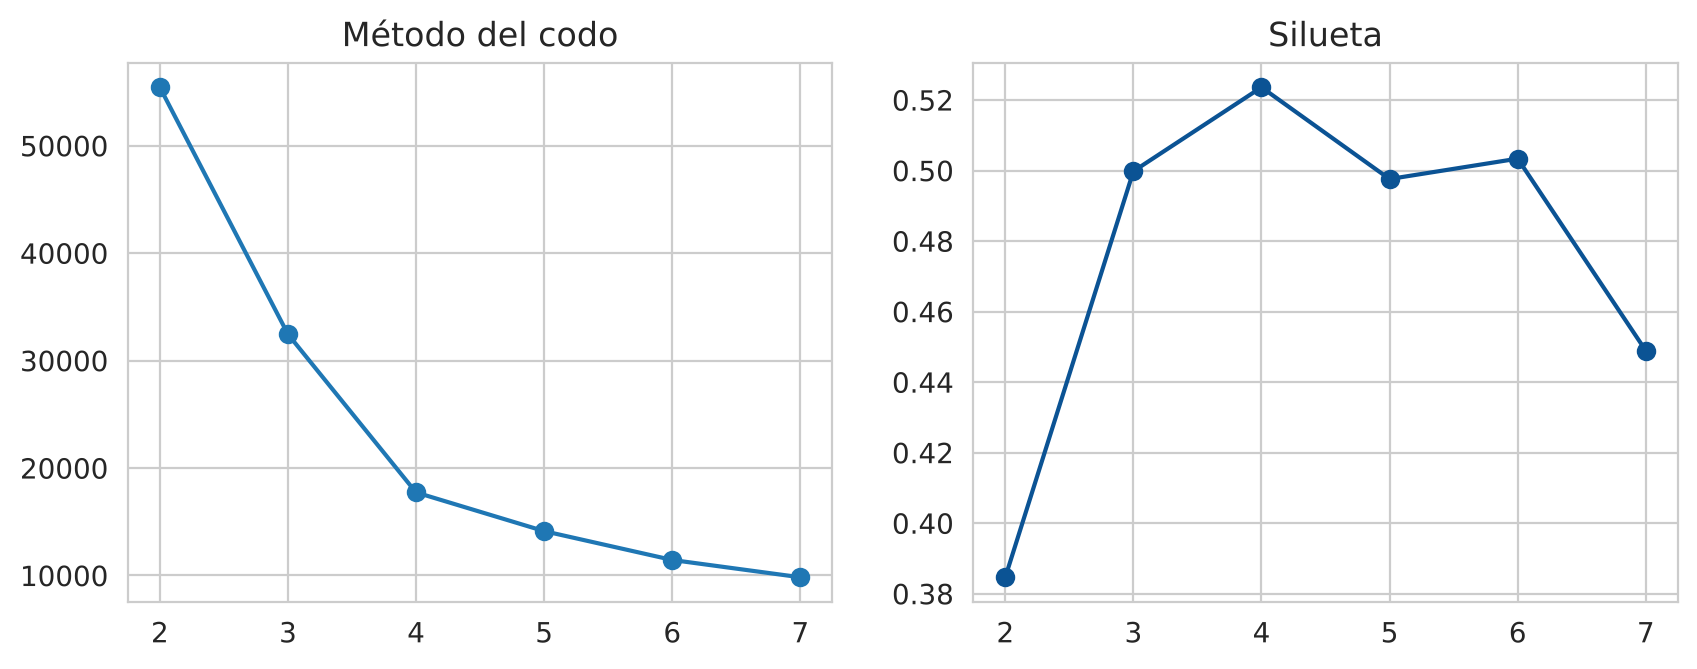

In [20]:
Z = StandardScaler().fit_transform(np.log1p(df[nav8]))
pca = PCA(n_components=3, random_state=SEMILLA).fit(Z)
Z_pca = pca.transform(Z)
print(f'Varianza explicada con 3 componentes: {pca.explained_variance_ratio_.sum():.1%}')

inercias, siluetas = {}, {}
for k in range(2, 8):
    km = KMeans(n_clusters=k, n_init=10, random_state=SEMILLA).fit(Z_pca)
    inercias[k] = km.inertia_
    siluetas[k] = silhouette_score(Z_pca, km.labels_, sample_size=5000, random_state=SEMILLA)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].plot(list(inercias), list(inercias.values()), 'o-'); ax[0].set_title('Método del codo')
ax[1].plot(list(siluetas), list(siluetas.values()), 'o-', color='#0B5394'); ax[1].set_title('Silueta')
plt.show()

In [21]:
km4 = KMeans(n_clusters=4, n_init=10, random_state=SEMILLA).fit(Z_pca)
df['cluster'] = km4.labels_
print(f'Silueta k = 4: {silhouette_score(Z_pca, km4.labels_):.3f}')
df.groupby('cluster')[nav8 + ['Revenue']].median().round(2)

Silueta k = 4: 0.525


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,Revenue
cluster,,,,,,,,,
0,0.000,0.000,0.000,0.000,12.000,370.750,0.000,0.040,0.000
1,0.000,0.000,0.000,0.000,1.000,0.000,0.200,0.200,0.000
2,4.000,109.800,2.000,89.000,43.000,1679.670,0.000,0.020,0.000
3,3.000,81.000,0.000,0.000,24.000,794.500,0.000,0.020,0.000


In [22]:
# Asigno los nombres del Frente 1 según el perfil (la numeración de K-Means es arbitraria)
conv = df.groupby('cluster')['Revenue'].mean().sort_values()
nombres_seg = dict(zip(conv.index, ['Rebote inmediato', 'Exploradores ligeros',
                                     'Navegación administrativa', 'Investigadores intensivos']))
df['segmento'] = df['cluster'].map(nombres_seg)
df.groupby('segmento')[['Administrative', 'ProductRelated', 'ProductRelated_Duration', 'ExitRates']].median()

,Administrative,ProductRelated,ProductRelated_Duration,ExitRates
segmento,,,,
Exploradores ligeros,0.000,12.000,370.750,0.036
Investigadores intensivos,4.000,43.000,1679.667,0.019
Navegación administrativa,3.000,24.000,794.500,0.018
Rebote inmediato,0.000,1.000,0.000,0.200


Para cruzar segmentos y probabilidades necesito una probabilidad para **todas** las sesiones, sin calificar sesiones con las que se entrenó el modelo. Uso probabilidades **fuera de muestra** (validación cruzada de 5 pliegues con el mismo pipeline final).

In [23]:
df['prob'] = cross_val_predict(pipe_final(), preparar_X(numericas), y, method='predict_proba',
                               cv=StratifiedKFold(5, shuffle=True, random_state=SEMILLA))[:, 1]
corte_alta = df['prob'].quantile(0.80)
print(f"AUC fuera de muestra: {roc_auc_score(y, df['prob']):.3f}  |  corte banda alta: {corte_alta:.3f}")

integ = df.groupby('segmento').agg(
    sesiones=('Revenue', 'size'), conversion=('Revenue', 'mean'), prob_media=('prob', 'mean'),
    pct_prob_020=('prob', lambda p: (p >= 0.20).mean()),
    pct_banda_alta=('prob', lambda p: (p >= corte_alta).mean()))
integ['% sesiones'] = integ['sesiones'] / len(df)
integ['% de compras'] = df.groupby('segmento')['Revenue'].sum() / y.sum()
integ['compradores potenciales (p≥0.20 sin compra)'] = df[(df['prob'] >= 0.20) & (y == 0)].groupby('segmento').size()
integ = integ.sort_values('conversion')
integ

AUC fuera de muestra: 0.750  |  corte banda alta: 0.256


,sesiones,conversion,prob_media,pct_prob_020,pct_banda_alta,% sesiones,% de compras,compradores potenciales (p≥0.20 sin compra)
segmento,,,,,,,,
Rebote inmediato,918,0.004,0.001,0.000,0.000,0.074,0.002,NaN
Exploradores ligeros,4984,0.106,0.107,0.156,0.091,0.404,0.276,541.000
Navegación administrativa,4215,0.201,0.198,0.423,0.260,0.342,0.444,1280.000
Investigadores intensivos,2213,0.239,0.244,0.596,0.414,0.179,0.277,916.000


In [24]:
# Conversión real dentro de cada segmento según su banda de probabilidad
df['banda'] = pd.cut(df['prob'], [0, 0.20, corte_alta, 1], labels=['p < 0.20', f'0.20–{corte_alta:.2f}', f'≥ {corte_alta:.2f}'],
                     include_lowest=True)
pd.crosstab(df['segmento'], df['banda'], values=df['Revenue'], aggfunc='mean').round(3)

banda,p < 0.20,0.20–0.26,≥ 0.26
segmento,,,
Exploradores ligeros,0.069,0.238,0.349
Investigadores intensivos,0.141,0.256,0.327
Navegación administrativa,0.142,0.196,0.337
Rebote inmediato,0.004,NaN,NaN


In [25]:
pd.crosstab(df['segmento'], df['banda'])

banda,p < 0.20,0.20–0.26,≥ 0.26
segmento,,,
Exploradores ligeros,4208,323,453
Investigadores intensivos,894,402,917
Navegación administrativa,2431,688,1096
Rebote inmediato,918,0,0


Ahora con las bandas del piloto (percentiles 50 y 80 de la probabilidad): ¿de qué segmentos está compuesta cada banda?

In [26]:
df['banda_piloto'] = pd.cut(df['prob'], [-1, df['prob'].quantile(0.5), corte_alta, 2], labels=['Baja', 'Media', 'Alta'])
print('Cortes:', df['prob'].quantile([0.5, 0.8]).round(3).tolist())
display(pd.crosstab(df['segmento'], df['banda_piloto'], normalize='columns').round(3))
pd.crosstab(df['segmento'], df['banda_piloto'], values=df['Revenue'], aggfunc='mean').round(3)

Cortes: [0.137, 0.256]


banda_piloto,Baja,Media,Alta
segmento,,,
Exploradores ligeros,0.578,0.261,0.184
Investigadores intensivos,0.061,0.248,0.372
Navegación administrativa,0.212,0.491,0.444
Rebote inmediato,0.149,0.000,0.000


banda_piloto,Baja,Media,Alta
segmento,,,
Exploradores ligeros,0.048,0.204,0.349
Investigadores intensivos,0.084,0.215,0.327
Navegación administrativa,0.126,0.174,0.337
Rebote inmediato,0.004,NaN,NaN


Esto es lo que faltó en la Actividad 3:
- **Rebote inmediato:** probabilidad media casi nula y ninguna sesión con p ≥ 0.20: no se interviene.
- **Exploradores ligeros:** 40% del tráfico, probabilidad media de 0.11. Solo una parte pequeña supera 0.20, y ahí está su potencial; el resto no justifica incentivos.
- **Navegación administrativa e Investigadores intensivos:** probabilidades medias de ~0.20–0.25 y el 82% de la banda alta. Muchos ya iban a comprar, así que un descuento les quitaría margen.
- **Navegación administrativa** aporta casi la mitad (49%) de la banda media, que es donde se probará el incentivo.

Esto **ajusta** la acción de la Actividad 3: el incentivo no debe ir a todos los exploradores ligeros con p > 0.20, sino a la banda intermedia de cada segmento, y en la banda alta conviene quitar fricción sin descuento.

### 5.1 Reviso el escenario hipotético de la Actividad 3
En la Actividad 3 dijimos que subir la conversión de los exploradores ligeros de 10.5% a 13% sumaría ~125 compras. Lo recalculo con la base.

In [27]:
n_lig = (df['segmento'] == 'Exploradores ligeros').sum()
conv_lig = df.loc[df['segmento'] == 'Exploradores ligeros', 'Revenue'].mean()
print(f'Sesiones del segmento: {n_lig:,}  | conversión actual: {conv_lig:.1%}')
print(f'Compras adicionales si llegara a 13% (sobre las 12,330 sesiones): {n_lig * (0.13 - conv_lig):.0f}')

Sesiones del segmento: 4,984  | conversión actual: 10.6%
Compras adicionales si llegara a 13% (sobre las 12,330 sesiones): 121


Sigue siendo un **escenario**, no un resultado: el piloto es lo que tiene que demostrar si una acción provoca compras adicionales.

## 6. Evaluation — estacionalidad y condiciones

Meses en la base: 10


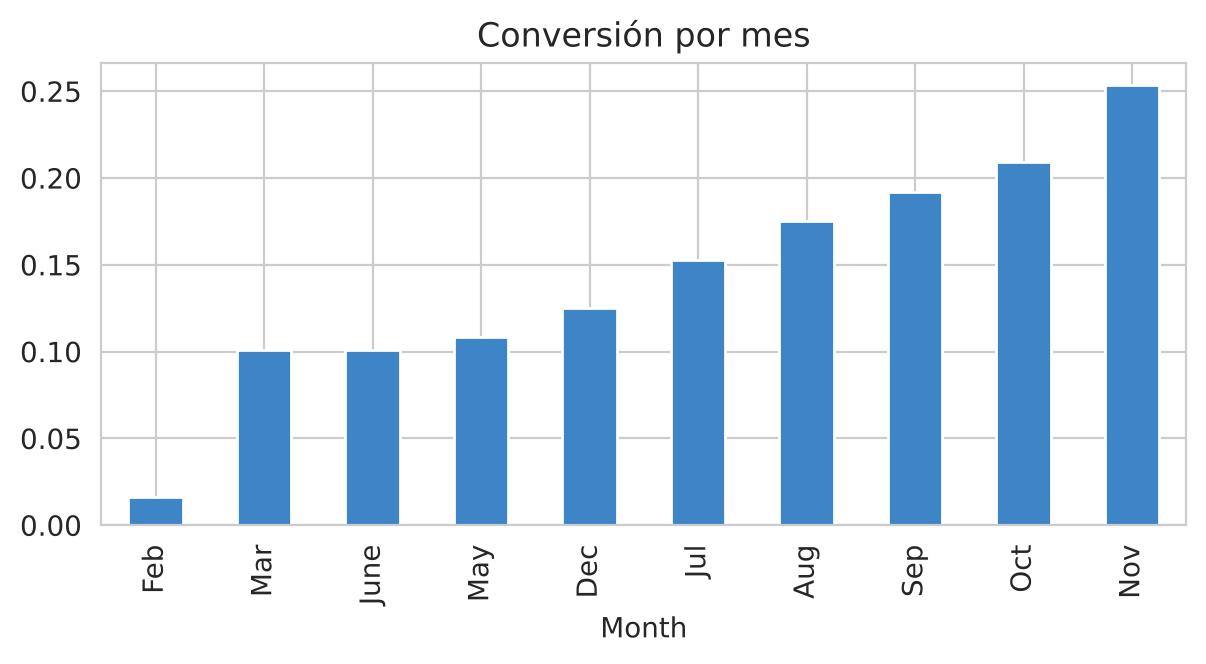

In [28]:
print('Meses en la base:', df['Month'].nunique())
df.groupby('Month')['Revenue'].mean().sort_values().plot(kind='bar', figsize=(7, 3), color='#3D85C6',
                                                         title='Conversión por mes')
plt.show()

La base solo tiene 10 meses y la conversión va de ~2% en febrero a ~25% en noviembre. Una comparación antes/después confundiría estacionalidad con efecto del piloto, así que la referencia debe ser un **grupo de control aleatorio** del mismo periodo.

**Lo demostrado (retrospectivo):** el modelo ordena sesiones de forma estable y concentra compradores.  
**Por validar:** desempeño con datos parciales en la 5.ª página, efecto causal de las acciones, valor económico y estabilidad por temporada.

## 7. Deployment — dimensionamiento del piloto (supuestos, no resultados)

In [29]:
sesiones_mes, semanas, pct_media = 12_000, 8, 0.30
sesiones_media = sesiones_mes * llega_5 * pct_media * semanas / 4.33
n_grupo = sesiones_media / 2
p_ref = tb.loc['Media (30%)', 'conversion']
mde = (norm.ppf(0.975) + norm.ppf(0.80)) * np.sqrt(2 * p_ref * (1 - p_ref) / n_grupo)
print(f'Sesiones en banda media en {semanas} semanas: ~{sesiones_media:,.0f} (~{n_grupo:,.0f} por grupo)')
print(f'Conversión de referencia en banda media: {p_ref:.1%}')
print(f'Diferencia mínima detectable (alfa 0.05, potencia 80%): ~{mde * 100:.1f} p.p.')

Sesiones en banda media en 8 semanas: ~5,579 (~2,790 por grupo)
Conversión de referencia en banda media: 17.3%
Diferencia mínima detectable (alfa 0.05, potencia 80%): ~2.8 p.p.


## 8. Resumen de cifras que usa el documento

In [30]:
rB = res_B.set_index('Modelo'); rA = res_A.set_index('Modelo')
pd.Series({
    'Conversión base': f'{tasa_base:.1%}',
    'AUC prueba sin PV (Log / LDA / NB)': ' / '.join(f"{rB.loc[m, 'AUC prueba']:.3f}" for m in rB.index),
    'AUC prueba con PV (Log / LDA / NB)': ' / '.join(f"{rA.loc[m, 'AUC prueba']:.3f}" for m in rA.index),
    'Logística sin PV @0.20: recall / precisión / F1': f"{rB.loc['Regresión logística', 'Recall@0.2']:.2f} / {rB.loc['Regresión logística', 'Precisión@0.2']:.2f} / {rB.loc['Regresión logística', 'F1@0.2']:.2f}",
    'CV 5x10 AUC': f"{cv_rep['test_roc_auc'].mean():.3f} ± {cv_rep['test_roc_auc'].std():.3f}",
    'Bootstrap OOB AUC (IC 95%)': f"{auc_boot.mean():.3f} ({np.percentile(auc_boot, 2.5):.3f}–{np.percentile(auc_boot, 97.5):.3f})",
    'Banda alta: conversión / % compras': f"{tb.iloc[2]['conversion']:.1%} / {tb.iloc[2]['% de compras']:.1%}",
    'Banda media: conversión / % compras': f"{tb.iloc[1]['conversion']:.1%} / {tb.iloc[1]['% de compras']:.1%}",
}, name='Valor').to_frame()

,Valor
Conversión base,15.5%
AUC prueba sin PV (Log / LDA / NB),0.742 / 0.726 / 0.707
AUC prueba con PV (Log / LDA / NB),0.911 / 0.910 / 0.842
Logística sin PV @0.20: recall / precisión / F1,0.61 / 0.29 / 0.40
CV 5x10 AUC,0.752 ± 0.013
Bootstrap OOB AUC (IC 95%),0.751 (0.734–0.768)
Banda alta: conversión / % compras,34.7% / 44.9%
Banda media: conversión / % compras,17.3% / 33.6%
